# P501 AD9361 quick operation test

Brings up the AD9361 from user space (no kernel driver), transmits tones on **TX1**, receives them on **RX1**, and plots what comes back.
Takes about a minute. Run the cells top to bottom; every section ends with a `PASS` / `FAIL` line and the last cell prints a summary.

**Setup:** the TX1 and RX1 antennas near each other (over-the-air loopback). If you use a cable instead, put **at least 40 dB of attenuation**
between TX1 and RX1 - never connect them directly. Details of the driver and test methods: `docs/AD9361_BRINGUP_REPORT.md` in the repository.

## 0. Configuration

In [1]:
FS        = 3_840_000      # sample rate: this notebook uses the 3.84 MSPS preset
LO        = 700_000_000    # RF centre frequency in Hz (70 MHz ... 6 GHz)
TONE      = 1_000_000      # test-tone offset from the LO in Hz
TX_ATTEN  = 10             # TX attenuation in dB (0 = maximum power); raise it if the receiver saturates
RX_GAIN   = 45             # RX gain-table index, 0 ... 76
N         = 8192           # samples per capture
RF_BW     = 4_000_000      # analog RF bandwidth in Hz
SETTLE_DB = 45             # image rejection (dB) the bring-up waits for, see section 1

In [2]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from pynq import Overlay, allocate

sys.path.insert(0, '/home/xilinx/jupyter_notebooks')
from ad9361_driver import (AD9361, FIR_RX1, FIR_TX1,
                           REG_ENSM_CONFIG_1, TO_ALERT, FORCE_ALERT_STATE)
from axi_dmac import AxiDmac
import ad9361_full_bypass_test as fb
from ad9361_fir_test import make_fir_coef

results = {}
def check(name, ok, detail):
    results[name] = (bool(ok), detail)
    print(f"{'PASS' if ok else 'FAIL'}  {name}: {detail}")

ol  = Overlay("base/system_top.bit")
txd = AxiDmac(ol.axi_ad9361_dac_dma)
rxd = AxiDmac(ol.axi_ad9361_adc_dma)
freqs = np.fft.fftshift(np.fft.fftfreq(N, d=1 / FS))
BIN = FS / N

def tone_buffer(f_hz, amp=0.5):
    """Complex tone with a whole number of cycles per buffer (no spectral leakage)."""
    cyc = round(f_hz * N / FS)
    t = np.exp(2j * np.pi * cyc * np.arange(N) / N) * amp * (2**15 - 1)
    tx = allocate(shape=(N * 2,), dtype=np.int16)           # interleaved I, Q
    tx[0::2] = t.real.astype(np.int16)
    tx[1::2] = t.imag.astype(np.int16)
    tx.flush()
    return tx, cyc * FS / N

def capture(tx=None):
    """Capture N samples from RX1 while (optionally) transmitting tx in a loop."""
    rx = allocate(shape=(N * 2,), dtype=np.int16)
    if tx is not None:
        txd.transfer_from_memory(tx.physical_address, tx.nbytes, cyclic=True)
    ok = rxd.transfer_to_memory(rx.physical_address, rx.nbytes)
    rx.invalidate()
    if tx is not None:
        txd.stop()
    a = np.array(rx)
    rx.freebuffer()
    x = a[0::2].astype(float) + 1j * a[1::2].astype(float)
    return ok, x - x.mean()

def spectrum_db(x):
    return 20 * np.log10(np.abs(np.fft.fftshift(np.fft.fft(x * np.hanning(len(x))))) + 1e-9)

def level(m, f0, w=25e3):
    return m[np.abs(freqs - f0) < w].max()

## 1. Bring-up

Locks the PLLs, programs the sample-rate chain, runs the receiver/transmitter calibrations and loads the filters.

The AD9361's analog section ends up in one of a few slightly different states every time it is enabled (about 3 dB and 9 dB apart,
image rejection 34 - 66 dB). `settle()` therefore checks the image rejection of a test tone and re-enables the chip until it is at least
`SETTLE_DB`. This is a workaround for a known open issue, described in the report.

In [3]:
def settle(ad, min_rej_db=SETTLE_DB, max_tries=40):
    tx, f = tone_buffer(TONE)
    for tries in range(1, max_tries + 1):
        ok, x = capture(tx)
        m = spectrum_db(x)
        rej = level(m, f) - level(m, -f)
        if rej >= min_rej_db:
            break
        ad.reg_write(REG_ENSM_CONFIG_1, TO_ALERT | FORCE_ALERT_STATE)   # ALERT ...
        if tries % 8 == 0:
            ad.tx_quad_calib(RF_BW // 2, RF_BW // 2)                     # sometimes recalibrate TX
        ad.enable_fdd()                                                  # ... -> FDD again
        fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)
    tx.freebuffer()
    return rej, tries

def bring_up(lo=LO):
    global ad
    try:
        ad.close()                              # re-running this cell: release the previous SPI handle
    except NameError:
        pass
    ad = AD9361()
    ad.power_up_clocks()
    assert ad.set_bbpll_rate(983_040_000), "BBPLL did not lock"
    ad.set_clock_chain()                                           # 3.84 MSPS
    ad.synth_cp_calib(False); ad.synth_cp_calib(True)
    rx_ok = ad.set_rx_lo_freq(lo)
    tx_ok = ad.set_tx_lo_freq(lo)
    ad.enable_rx1_tx1()
    fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)       # FPGA side: R1 mode, DAC datarate 1
    ad.reg_write(fb.REG_PARALLEL_PORT_CONF_1, fb.PP_CONF_1)
    ad.reg_write(fb.REG_PARALLEL_PORT_CONF_2, fb.PP_CONF_2)
    ad.reg_write(fb.REG_PARALLEL_PORT_CONF_3, fb.PP_CONF_3_LVDS_MODE)
    ad.reg_write(fb.REG_RX_CLOCK_DATA_DELAY, fb.RX_CLOCK_DATA_DELAY)
    ad.reg_write(fb.REG_TX_CLOCK_DATA_DELAY, fb.TX_CLOCK_DATA_DELAY)
    ad.reg_write(fb.REG_LVDS_BIAS_CTRL, fb.LVDS_BIAS_CTRL)
    cal = ad.analog_init(rf_rx_bw_hz=RF_BW, rf_tx_bw_hz=RF_BW, rx_freq_hz=lo)
    ad.set_rx_manual_gain(RX_GAIN)
    ad.set_tx_atten_db(TX_ATTEN)
    ad.enable_fdd()
    coef = make_fir_coef()
    ad.load_fir_filter_coef(FIR_RX1, 0, coef)
    ad.load_fir_filter_coef(FIR_TX1, 0, coef)
    fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)
    return rx_ok, tx_ok, cal

rx_ok, tx_ok, cal = bring_up()
rej, tries = settle(ad)
print(f"AD9361 product id 0x{ad.product_id():02X}   ENSM state 0x{ad.ensm_state():X} (0xA = FDD)")
print(f"RX LO locked: {rx_ok}   TX LO locked: {tx_ok}")
print("calibrations:", cal)
print(f"interface clock count {ol.axi_ad9361.read(0x54):#x} (0x13A9 = 7.68 MHz = 2 x fs in 1R1T)   settled after {tries} tries, image rejection {rej:.1f} dB")

check("chip identity", ad.product_id_ok(), f"product id 0x{ad.product_id():02X}")
check("PLL lock + FDD", rx_ok and tx_ok and ad.ensm_state() == 0xA, f"RX {rx_ok}, TX {tx_ok}, ENSM 0x{ad.ensm_state():X}")
check("calibrations", all(v is True or v == 3 for v in cal.values()), str(cal))

AD9361 product id 0x0A   ENSM state 0xA (0xA = FDD)
RX LO locked: True   TX LO locked: True
calibrations: {'rx_bb_filter': True, 'tx_bb_filter': True, 'bb_dc': True, 'rf_dc': True, 'tx_quad': 3}
interface clock count 0x13a9 (0x13A9 = 7.68 MHz = 2 x fs in 1R1T)   settled after 7 tries, image rejection 45.2 dB
PASS  chip identity: product id 0x0A
PASS  PLL lock + FDD: RX True, TX True, ENSM 0xA
PASS  calibrations: {'rx_bb_filter': True, 'tx_bb_filter': True, 'bb_dc': True, 'rf_dc': True, 'tx_quad': 3}


## 2. One tone, TX1 -> RX1

Transmits `TONE` above the LO and captures the received signal. Expect a single sharp line at the tone frequency, the mirror image
well below it, and a small DC spike at 0 (LO leakage).

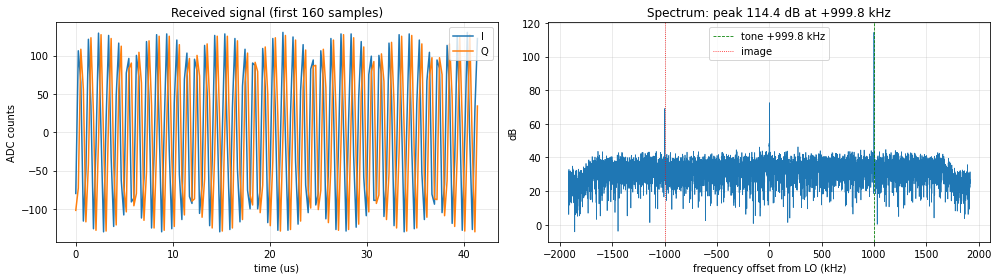

PASS  DMA transfer: capture completed
PASS  tone frequency: peak at +999.84 kHz, expected +999.84 kHz
PASS  tone level: 81.3 dB above the noise floor
PASS  image rejection: 45.3 dB


In [4]:
tx, f = tone_buffer(TONE)
ok, x = capture(tx)
tx.freebuffer()
m = spectrum_db(x)
i = int(np.argmax(m))
peak_f, peak_db = freqs[i], m[i]
image_db, floor_db = level(m, -f), float(np.median(m))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
t_us = np.arange(160) / FS * 1e6
ax[0].plot(t_us, x[:160].real, label="I")
ax[0].plot(t_us, x[:160].imag, label="Q")
ax[0].set(title="Received signal (first 160 samples)", xlabel="time (us)", ylabel="ADC counts"); ax[0].legend(loc="upper right"); ax[0].grid(alpha=.3)
ax[1].plot(freqs / 1e3, m, lw=0.7)
ax[1].axvline(f / 1e3, color="g", ls="--", lw=0.8, label=f"tone {f/1e3:+.1f} kHz")
ax[1].axvline(-f / 1e3, color="r", ls=":", lw=0.8, label="image")
ax[1].set(title=f"Spectrum: peak {peak_db:.1f} dB at {peak_f/1e3:+.1f} kHz", xlabel="frequency offset from LO (kHz)", ylabel="dB")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

check("DMA transfer", ok, "capture completed")
check("tone frequency", abs(peak_f - f) < 2 * BIN, f"peak at {peak_f/1e3:+.2f} kHz, expected {f/1e3:+.2f} kHz")
check("tone level", peak_db - floor_db > 40, f"{peak_db - floor_db:.1f} dB above the noise floor")
check("image rejection", peak_db - image_db > 30, f"{peak_db - image_db:.1f} dB")

## 3. Tone sweep

Six tones from -1.5 to +1.5 MHz. Each peak must land on the commanded frequency **with the right sign** (a tone at -1 MHz must not appear at +1 MHz),
which verifies the I/Q orientation end to end.

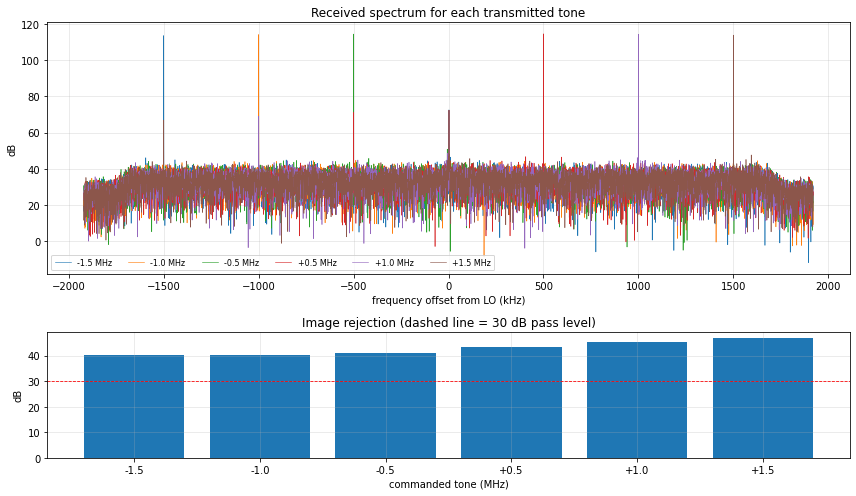

 commanded   received   peak dB  rejection dB
  -1500.0k   -1500.0k     113.6          40.1
  -1000.0k    -999.8k     114.2          40.1
   -500.0k    -500.2k     114.5          40.8
    500.0k     500.2k     114.6          43.4
   1000.0k     999.8k     114.4          45.3
   1500.0k    1500.0k     113.9          46.9
PASS  sweep frequency and sign: all six peaks on the commanded frequency
PASS  sweep image rejection: worst 40.1 dB


In [5]:
tones = [-1.5e6, -1.0e6, -0.5e6, 0.5e6, 1.0e6, 1.5e6]
rows = []
fig, ax = plt.subplots(2, 1, figsize=(12, 7), gridspec_kw={"height_ratios": [2, 1]})
for tgt in tones:
    txb, ft = tone_buffer(tgt)
    okc, xs = capture(txb)
    txb.freebuffer()
    ms = spectrum_db(xs)
    k = int(np.argmax(ms))
    rows.append((tgt, ft, freqs[k], ms[k], ms[k] - level(ms, -ft)))
    ax[0].plot(freqs / 1e3, ms, lw=0.6, label=f"{tgt/1e6:+.1f} MHz")
ax[0].set(title="Received spectrum for each transmitted tone", xlabel="frequency offset from LO (kHz)", ylabel="dB")
ax[0].legend(ncol=6, fontsize=8); ax[0].grid(alpha=.3)
ax[1].bar([f"{r[0]/1e6:+.1f}" for r in rows], [r[4] for r in rows], color="tab:blue")
ax[1].axhline(30, color="r", ls="--", lw=0.8)
ax[1].set(title="Image rejection (dashed line = 30 dB pass level)", xlabel="commanded tone (MHz)", ylabel="dB"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"{'commanded':>10} {'received':>10} {'peak dB':>9} {'rejection dB':>13}")
for tgt, ft, pf, pdb, rj in rows:
    print(f"{tgt/1e3:>9.1f}k {pf/1e3:>9.1f}k {pdb:>9.1f} {rj:>13.1f}")
check("sweep frequency and sign", all(abs(r[2] - r[1]) < 2 * BIN for r in rows), "all six peaks on the commanded frequency")
check("sweep image rejection", min(r[4] for r in rows) > 30, f"worst {min(r[4] for r in rows):.1f} dB")

## 4. TX attenuation

The received tone level should fall 1 dB for every 1 dB of TX attenuation (as long as the receiver is not saturated and the signal is above the noise).

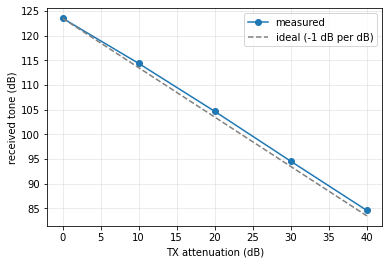

PASS  TX attenuator: max deviation from ideal 1.2 dB over 0...40 dB


In [6]:
atts = [0, 10, 20, 30, 40]
txb, f = tone_buffer(TONE)
lv = []
for a in atts:
    ad.set_tx_atten_db(a)
    okc, xs = capture(txb)
    lv.append(level(spectrum_db(xs), f))
ad.set_tx_atten_db(TX_ATTEN)
txb.freebuffer()
lv = np.array(lv)

plt.figure(figsize=(6, 4))
plt.plot(atts, lv, "o-", label="measured")
plt.plot(atts, lv[0] - np.array(atts), "--", color="gray", label="ideal (-1 dB per dB)")
plt.xlabel("TX attenuation (dB)"); plt.ylabel("received tone (dB)"); plt.grid(alpha=.3); plt.legend(); plt.show()

err = np.max(np.abs((lv[0] - lv) - np.array(atts)))
check("TX attenuator", err < 3, f"max deviation from ideal {err:.1f} dB over {atts[0]}...{atts[-1]} dB")

## 5. Summary

In [7]:
width = max(len(k) for k in results)
for name, (ok, detail) in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name:<{width}}  {detail}")
print()
print("ALL TESTS PASSED" if all(ok for ok, _ in results.values()) else "SOME TESTS FAILED - see above")

PASS  chip identity             product id 0x0A
PASS  PLL lock + FDD            RX True, TX True, ENSM 0xA
PASS  calibrations              {'rx_bb_filter': True, 'tx_bb_filter': True, 'bb_dc': True, 'rf_dc': True, 'tx_quad': 3}
PASS  DMA transfer              capture completed
PASS  tone frequency            peak at +999.84 kHz, expected +999.84 kHz
PASS  tone level                81.3 dB above the noise floor
PASS  image rejection           45.3 dB
PASS  sweep frequency and sign  all six peaks on the commanded frequency
PASS  sweep image rejection     worst 40.1 dB
PASS  TX attenuator             max deviation from ideal 1.2 dB over 0...40 dB

ALL TESTS PASSED


### Next steps

* Another frequency: set `LO` in section 0 (e.g. `433_000_000`, `2_400_000_000`, `5_800_000_000`) and re-run from section 1.
  The receiver gain tables cover 70 MHz - 6 GHz; image rejection varies a little with frequency and the `SETTLE_DB` target may need lowering
  (it is not reachable at some LOs, see the report).
* Free the SPI handle when you are done: run `ad.close()`.
* 2x2 MIMO and higher sample rates (30.72 / 61.44 MSPS): `ad9361_mimo_test.py`, `ad9361_rate_test.py`.